In [1]:
# Run once if needed
# %pip install neurokit2
# !pip install lightgbm neurokit2

In [2]:
import h5py

import glob
import os

import numpy as np
import pandas as pd
import neurokit2 as nk
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor

# from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
"""
Load data setup
"""
#Setup for processing all records 
data_folder = "data/cuff+less+blood+pressure+estimation"

sampling_rate = 125
window_seconds = 5
window_size = sampling_rate * window_seconds   # 625 samples

In [4]:
"""
Helper functions
"""
# Normalize
def normalize(signal):
    """
    Standardize signal:
    mean = 0
    standard deviation = 1
    """
    std = np.std(signal)

    if std == 0:
        return signal

    return (signal - np.mean(signal)) / std

# Get features
def get_features(signal):
    """
    Extract simple statistical features from one 5-second signal
    """
    features = [
        np.mean(signal),
        np.std(signal),
        np.min(signal),
        np.max(signal),
        np.median(signal),
        np.max(signal) - np.min(signal)
    ]
    return features

# Name features to make LightGBM results easier to understand
feature_names = [
    "PPG_mean",
    "PPG_std",
    "PPG_min",
    "PPG_max",
    "PPG_median",
    "PPG_range",

    "ECG_mean",
    "ECG_std",
    "ECG_min",
    "ECG_max",
    "ECG_median",
    "ECG_range"
]

In [5]:
### Storage
all_features = []

all_sbp = []
all_dbp = []

all_groups = []


### Check all .MAT files are found
mat_files = sorted(
    glob.glob(os.path.join(data_folder, "Part_*.mat")))

print("Files found:")

for file in mat_files:
    print(file)

print("\nTotal files:", len(mat_files))

Files found:
data/cuff+less+blood+pressure+estimation\Part_1.mat
data/cuff+less+blood+pressure+estimation\Part_2.mat
data/cuff+less+blood+pressure+estimation\Part_3.mat
data/cuff+less+blood+pressure+estimation\Part_4.mat

Total files: 4


In [9]:
# Change the value of num_parts to process that number of .mat files
## num_parts = 1 --> Part_1 only
## num_parts = 2 --> Part_1 + Part_2
## num_parts = 3 --> Part_1 + Part_2 + Part_3
## num_parts = 4 --> all parts

num_parts = 2
mat_files = sorted(glob.glob(os.path.join(data_folder, "Part_*.mat")))

num_parts = min(num_parts, len(mat_files))

mat_files = mat_files[:num_parts]

print(f"Processing {len(mat_files)} parts:")
for file in mat_files:
    print(" -", os.path.basename(file))

Processing 2 parts:
 - Part_1.mat
 - Part_2.mat


In [8]:
"""
Pre-processing designated number of files and records

Takes a few minutes to fully run, because it is processing designated number of .mat files.
Works with all 4 .mat files.
"""
total_records = 0
used_records = 0
skipped_records = 0


for file_path in mat_files:
    file_name = os.path.basename(file_path)

    # Example:
    # Part_1.mat -> Part_1
    dataset_name = os.path.splitext(file_name)[0]

    print("\nProcessing:", file_name)

    with h5py.File(file_path, "r") as f:
        data = f[dataset_name]

        # Flatten references so this works whether MATLAB stored
        # them as (1, N) or (N, 1)
        references = np.array(data).flatten()

        print("Records:", len(references))

        for record_number, ref in enumerate(references):
            total_records += 1

            # Give every record its own ID
            record_id = f"{dataset_name}_record_{record_number}"

            try:
                # --------------------------------------------
                # Load record
                # --------------------------------------------
                record = np.array(f[ref])

                # --------------------------------------------
                # Get signals and check orientation
                # --------------------------------------------
                # Official dataset states:
                # row 0 = PPG
                # row 1 = ABP
                # row 2 = ECG

                # If rows are signals and columns are samples
                if record.shape[0] == 3:
                    ppg = record[0]
                    abp = record[1]
                    ecg = record[2]
                    
                # If rows are samples and columns are signals
                elif record.shape[1] == 3:
                    ppg = record[:, 0]
                    abp = record[:, 1]
                    ecg = record[:, 2]


                else:
                    print("Skipping", record_id, "- unexpected shape:", record.shape)
                    skipped_records += 1
                    continue

                # Convert to normal 1D arrays
                ppg = np.asarray(ppg).flatten()
                abp = np.asarray(abp).flatten()
                ecg = np.asarray(ecg).flatten()

                # --------------------------------------------
                # Replace NaN and infinite values
                # --------------------------------------------
                ppg = np.nan_to_num(ppg, nan=0, posinf=0, neginf=0)
                abp = np.nan_to_num(abp, nan=0, posinf=0, neginf=0)
                ecg = np.nan_to_num(ecg, nan=0, posinf=0, neginf=0)
 
                # --------------------------------------------
                # CHECK RECORD LENGTH
                # --------------------------------------------
                # Need at least one complete 5-second window

                if len(ppg) < window_size:

                    skipped_records += 1
                    continue

                # --------------------------------------------
                # Clean PPG + ECG signals using NeuroKit
                # --------------------------------------------
                ppg_clean = nk.ppg_clean(
                    ppg,
                    sampling_rate=sampling_rate
                )

                ecg_clean = nk.ecg_clean(
                    ecg,
                    sampling_rate=sampling_rate
                )
                # Left ABP untouched because we need the actual pressure values for the labels

                # --------------------------------------------
                # Normalize
                # --------------------------------------------
                ppg_clean = normalize(ppg_clean)
                ecg_clean = normalize(ecg_clean)

                # --------------------------------------------
                # Create windows
                # --------------------------------------------
                valid_windows_in_record = 0

                for start in range(
                    0,
                    len(ppg_clean) - window_size + 1,
                    window_size
                ):

                    end = start + window_size

                    ppg_window = ppg_clean[start:end]
                    ecg_window = ecg_clean[start:end]
                    abp_window = abp[start:end]
                    
                    # ----------------------------------------
                    # BP labels
                    # ----------------------------------------
                    sbp = np.max(abp_window)
                    dbp = np.min(abp_window)

                    # ----------------------------------------
                    # Remove obviously bad BP windows
                    # ----------------------------------------
                    if not (
                        70 <= sbp <= 200
                        and 40 <= dbp <= 130
                        and sbp > dbp
                    ):

                        continue

                    # ----------------------------------------
                    # Extract features from both PPG and ECG
                    # ----------------------------------------
                    ppg_features = get_features(ppg_window)
                    ecg_features = get_features(ecg_window)
                    
                    features = (ppg_features + ecg_features)
                    
                    # Check features are valid
                    if not np.all(
                        np.isfinite(features)
                    ):
                        continue

                    # ----------------------------------------
                    # Save window
                    # ----------------------------------------
                    all_features.append(features)
                    all_sbp.append(sbp)
                    all_dbp.append(dbp)
                    all_groups.append(record_id)

                    valid_windows_in_record += 1

                if valid_windows_in_record > 0:
                    used_records += 1

            except Exception as error:
                print("Skipping", record_id, "because:", error)

                skipped_records += 1


# ============================================================
# Create final dataset
# ============================================================

X = pd.DataFrame(all_features, columns=feature_names)

sbp = np.array(all_sbp)
dbp = np.array(all_dbp)
groups = np.array(all_groups)


print("\n==============================")
print("PREPROCESSING SUMMARY")
print("==============================")

print("Total records found:", total_records)
print("Records used:", used_records)
print("Records skipped:", skipped_records)

print("Total valid windows:", len(X))

print("\nX shape:", X.shape)
print("SBP shape:", sbp.shape)
print("DBP shape:", dbp.shape)

print("Unique record groups:", len(np.unique(groups)))

print("\nFirst rows:")
print(X.head())


Processing: Part_1.mat
Records: 3000

Processing: Part_2.mat
Records: 3000

PREPROCESSING SUMMARY
Total records found: 6000
Records used: 5995
Records skipped: 0
Total valid windows: 505466

X shape: (505466, 12)
SBP shape: (505466,)
DBP shape: (505466,)
Unique record groups: 5995

First rows:
   PPG_mean   PPG_std   PPG_min   PPG_max  PPG_median  PPG_range  ECG_mean  \
0 -0.004614  0.973149 -1.254790  1.897492   -0.365004   3.152282  0.046748   
1 -0.033323  0.994794 -1.359514  1.819913   -0.400515   3.179427  0.011161   
2  0.036711  1.015251 -1.317058  1.898000   -0.296106   3.215058  0.007065   
3  0.003634  0.992296 -1.409642  1.891001   -0.343577   3.300643 -0.027281   
4 -0.033276  1.001929 -1.368858  1.852828   -0.404600   3.221686  0.009044   

    ECG_std   ECG_min   ECG_max  ECG_median  ECG_range  
0  1.026313 -1.655830  4.865673   -0.093302   6.521503  
1  0.973934 -1.522470  4.363141   -0.063258   5.885612  
2  1.042144 -1.559639  4.757054   -0.125677   6.316693  
3  1.00

In [10]:
"""
Create train / test split by record using GroupShuffleSplit
"""
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_index, test_index = next(
    group_split.split(X, sbp, groups=groups))

X_train = X.iloc[train_index]
X_test = X.iloc[test_index]

sbp_train = sbp[train_index]
sbp_test = sbp[test_index]

dbp_train = dbp[train_index]
dbp_test = dbp[test_index]

train_groups = groups[train_index]
test_groups = groups[test_index]

print("Training windows:", len(X_train))
print("Testing windows:", len(X_test))

print("Training records:", len(np.unique(train_groups)))
print("Testing records:", len(np.unique(test_groups)))

Training windows: 401448
Testing windows: 104018
Training records: 4796
Testing records: 1199


In [11]:
# Make sure there is no overlap
train_record_set = set(train_groups)
test_record_set = set(test_groups)

overlap = (train_record_set.intersection(test_record_set))

print("Records appearing in both sets:", len(overlap))

Records appearing in both sets: 0


In [12]:
"""
Create models and hyperparameters
"""
# Create models - Train one model for SBP, one model for DBP

# n_estimators - controls how many boosted trees are trained
# learning_rate - controls how strongly each new tree contributes.
sbp_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42
)

dbp_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42
)

"""
Train models 
"""
sbp_model.fit(X_train, sbp_train)
dbp_model.fit(X_train, dbp_train)

"""
Make predictions
"""
sbp_pred = sbp_model.predict(X_test)
dbp_pred = dbp_model.predict(X_test)

print("Actual SBP:", sbp_test[:5])
print("Predicted SBP:", sbp_pred[:5])

print("Actual DBP:", dbp_test[:5])
print("Predicted DBP:", dbp_pred[:5])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003554 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3060
[LightGBM] [Info] Number of data points in the train set: 401448, number of used features: 12
[LightGBM] [Info] Start training from score 134.168065
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014135 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3060
[LightGBM] [Info] Number of data points in the train set: 401448, number of used features: 12
[LightGBM] [Info] Start training from score 64.866071
Actual SBP: [131.24410818 129.82762916 129.68109684 129.09496759 128.50883834]
Predicted SBP: [138.47871126 140.18147229 140.78495234 138.53999498 139.80038216]
Actual DBP: [71.21470403 68.91903113 70.48204247 68.28405777 68.87018702]
Predicted DB

In [13]:
"""
Evaluate the model
"""
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    
    print("\n" + name)

    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R²:", round(r2, 3))

# Uses the defined function
evaluate_model("SBP Results", sbp_test, sbp_pred)
evaluate_model("DBP Results", dbp_test, dbp_pred)


SBP Results
MAE: 15.3
RMSE: 19.56
R²: 0.279

DBP Results
MAE: 7.51
RMSE: 9.97
R²: 0.251


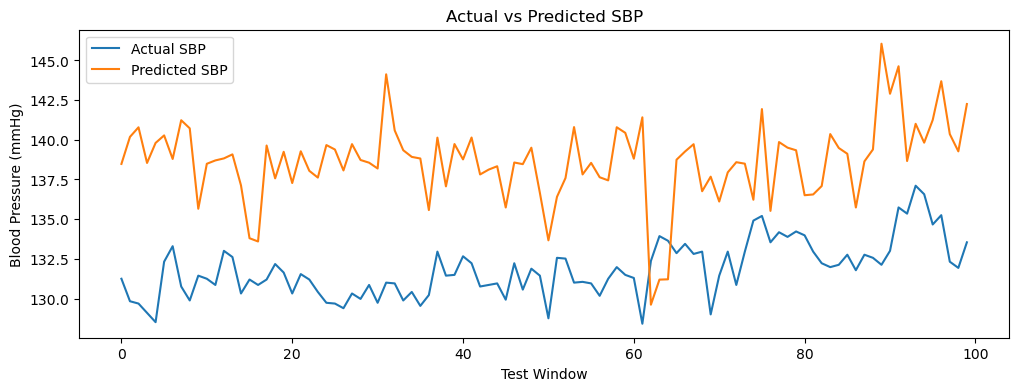

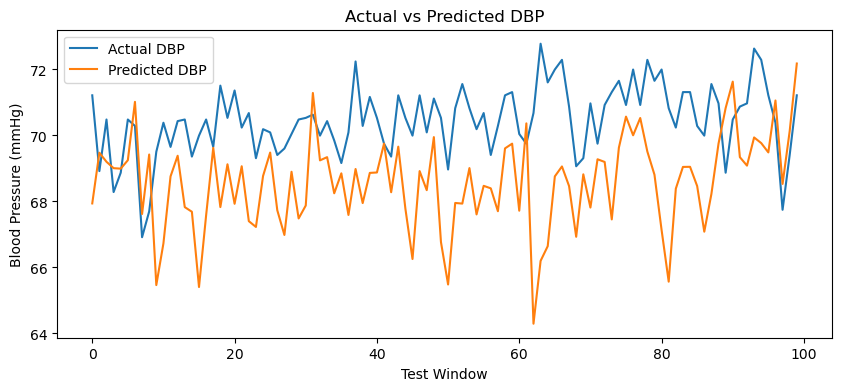

In [14]:
# Graph actual vs predicted BP
# Only graph first 100 test windows so it stays readable
# SBP
plt.figure(figsize=(12, 4))

plt.plot(sbp_test[:100], label="Actual SBP")
plt.plot(sbp_pred[:100], label="Predicted SBP")

plt.title("Actual vs Predicted SBP")
plt.xlabel("Test Window")
plt.ylabel("Blood Pressure (mmHg)")

plt.legend()
plt.show()

# DBP
plt.figure(figsize=(10, 4))

plt.plot(dbp_test[:100], label="Actual DBP")
plt.plot(dbp_pred[:100], label="Predicted DBP")

plt.title("Actual vs Predicted DBP")
plt.xlabel("Test Window")
plt.ylabel("Blood Pressure (mmHg)")

plt.legend()
plt.show()

In [15]:
"""
Check feature importance
"""
# LightGBM lets you cehck which features were the most useful
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": sbp_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

       Feature  Importance
10  ECG_median        1197
8      ECG_min        1008
9      ECG_max         907
4   PPG_median         535
11   ECG_range         525
3      PPG_max         507
2      PPG_min         493
7      ECG_std         348
5    PPG_range         187
1      PPG_std         152
0     PPG_mean          83
6     ECG_mean          58


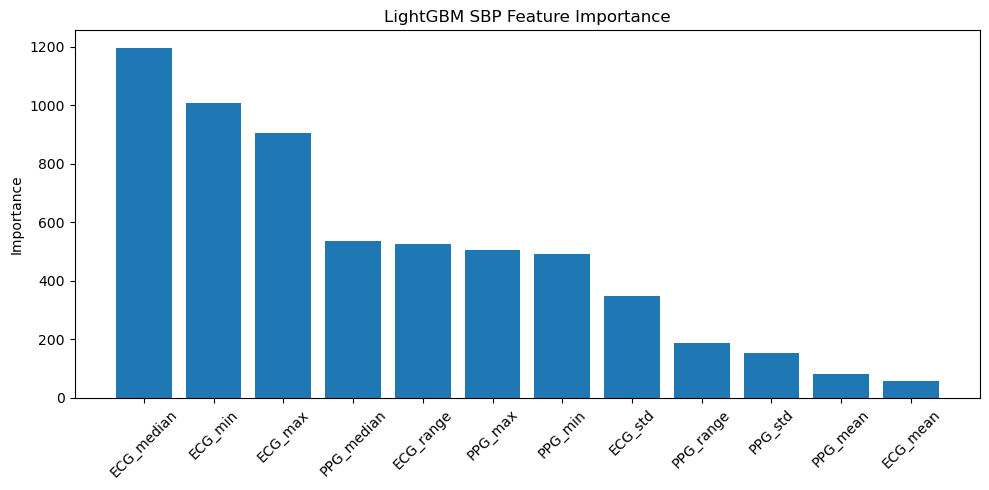

In [16]:
"""
Graph importance features 
"""
# Graphs the results
plt.figure(figsize=(10, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xticks(rotation=45)
plt.title("LightGBM SBP Feature Importance")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()

# Cell below was used to test code workflow only for one record

In [ ]:
import h5py
import numpy as np
import pandas as pd
import neurokit2 as nk
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Load data 
file_path = "data/cuff+less+blood+pressure+estimation/Part_1.mat"

with h5py.File(file_path, "r") as f:
    data = f["Part_1"]

    # First record
    ref = data[0, 0]
    record = np.array(f[ref])


#Get signals
# Official dataset states:
# row 0 = PPG
# row 1 = ABP
# row 2 = ECG

print("Record shape:", record.shape)
# Dataset might be shaped:
# (samples, 3)
# OR
# (3, samples)

# If rows are samples and columns are signals
if record.shape[1] == 3:
    ppg = record[:, 0]
    abp = record[:, 1]
    ecg = record[:, 2]

# If rows are signals and columns are samples
else:
    ppg = record[0]
    abp = record[1]
    ecg = record[2]

print("PPG:", ppg.shape)
print("ABP:", abp.shape)
print("ECG:", ecg.shape)


# Replace NaN and infinite values
ppg = np.nan_to_num(ppg)
abp = np.nan_to_num(abp)
ecg = np.nan_to_num(ecg) 

#Clean signals using NeuroKit
sampling_rate = 125

ppg_clean = nk.ppg_clean(
    ppg,
    sampling_rate=sampling_rate
)

ecg_clean = nk.ecg_clean(
    ecg,
    sampling_rate=sampling_rate
)

# Left ABP untouched because we need the actual pressure values for the labels


#Normalize
def normalize(signal):
    std = np.std(signal)

    if std == 0:
        return signal

    return (signal - np.mean(signal)) / std

ppg_clean = normalize(ppg_clean)
ecg_clean = normalize(ecg_clean)


#Make 5-second windows
window_seconds = 5
sampling_rate = 125
window_size = sampling_rate * window_seconds

print("Samples per window:", window_size)

ppg_windows = []
ecg_windows = []
abp_windows = []

for start in range(0, len(ppg_clean) - window_size + 1, window_size):
    end = start + window_size

    ppg_windows.append(ppg_clean[start:end])
    ecg_windows.append(ecg_clean[start:end])
    abp_windows.append(abp[start:end])

ppg_windows = np.array(ppg_windows)
ecg_windows = np.array(ecg_windows)
abp_windows = np.array(abp_windows)

print("PPG windows:", ppg_windows.shape)
print("PPG contains NaN:", np.isnan(ppg_windows).any())

print("ECG windows:", ecg_windows.shape)
print("ECG contains NaN:", np.isnan(ecg_windows).any())

print("ABP windows:", abp_windows.shape)
print("ABP contains NaN:", np.isnan(abp_windows).any())


# Graphs from initial preprocessing
# window = 0

# #PPG
# plt.figure(figsize=(12, 4))
# plt.plot(ppg_windows[window])
# plt.title("PPG Signal - 5 Second Window")
# plt.xlabel("Sample")
# plt.ylabel("PPG")
# plt.show()

# #ECG
# plt.figure(figsize=(12, 4))
# plt.plot(ecg_windows[window])
# plt.title("ECG Signal - 5 Second Window")
# plt.xlabel("Sample")
# plt.ylabel("ECG")
# plt.show()

# #ABP
# plt.figure(figsize=(12, 4))
# plt.plot(abp_windows[window])
# plt.title("ABP Signal - 5 Second Window")
# plt.xlabel("Sample")
# plt.ylabel("Blood Pressure (mmHg)")
# plt.show()



# LightGBM feature engineering

# calculate:
# - mean
# - standard deviation
# - minimum
# - maximum
# - median
# - range
def get_features(signal):
    features = [
        np.mean(signal),
        np.std(signal),
        np.min(signal),
        np.max(signal),
        np.median(signal),
        np.max(signal) - np.min(signal)
    ]
    return features

# Extract features from both PPG and ECG
X = []

for i in range(len(ppg_windows)):

    ppg_features = get_features(ppg_windows[i])
    ecg_features = get_features(ecg_windows[i])

    # Combine PPG + ECG features
    features = ppg_features + ecg_features

    X.append(features)


X = np.array(X)

print("X shape:", X.shape)

# Name features to make LightGBM results easier to understand
feature_names = [
    "PPG_mean",
    "PPG_std",
    "PPG_min",
    "PPG_max",
    "PPG_median",
    "PPG_range",

    "ECG_mean",
    "ECG_std",
    "ECG_min",
    "ECG_max",
    "ECG_median",
    "ECG_range"
]

X = pd.DataFrame(
    X,
    columns=feature_names
)

X.head()

# Create SBP and DBP labels, then checks them

# Can later improve by detecting actual ABP 
# systolic peaks and diastolic troughs instead of using absolute max/min
sbp = np.max(abp_windows, axis=1)
dbp = np.min(abp_windows, axis=1)

print("SBP:")
print(sbp[:10])

print("\nDBP:")
print(dbp[:10])


# 7. Remove obviously bad BP windows

# Limits are a quality-control basline, not a universal medical rule
valid = (
    (sbp >= 70) &
    (sbp <= 200) &
    (dbp >= 40) &
    (dbp <= 130) &
    (sbp > dbp)
)

X = X[valid].reset_index(drop=True)

sbp = sbp[valid]
dbp = dbp[valid]

print("Number of windows remaining:", len(X))


# Train / test split

# Future improvement - split by record/patient to prevent data leakage
# Look into - GroupShuffleSplit - exists specifically for splitting observations according to groups
X_train, X_test, sbp_train, sbp_test, dbp_train, dbp_test = train_test_split(
    X,
    sbp,
    dbp,
    test_size=0.2,
    random_state=42
)


# Create models
# Train one model for SBP, one model for DBP

# n_estimators - controls how many boosted trees are trained
# learning_rate - controls how strongly each new tree contributes.

# Try when training on laregr windows and all parts:
# n_estimators=200
# num_leaves=31

sbp_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42
)


dbp_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42
)

# train models

sbp_model.fit(
    X_train,
    sbp_train
)

dbp_model.fit(
    X_train,
    dbp_train
)


# Make predictions
sbp_pred = sbp_model.predict(X_test)
dbp_pred = dbp_model.predict(X_test)

print("Actual SBP:", sbp_test[:5])
print("Predicted SBP:", sbp_pred[:5])

print("Actual DBP:", dbp_test[:5])
print("Predicted DBP:", dbp_pred[:5])


# Evaluate the model
def evaluate_model(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R²:", round(r2, 2))

# Print SBP evaluation results
print("SBP Results")

evaluate_model(
    sbp_test,
    sbp_pred
)

# Print DBP evaluation results
print("DBP Results")

evaluate_model(
    dbp_test,
    dbp_pred
)


# Graph actual vs predicted BP

# SBP
plt.figure(figsize=(10, 4))

plt.plot(sbp_test, label="Actual SBP")
plt.plot(sbp_pred, label="Predicted SBP")

plt.title("Actual vs Predicted SBP")
plt.xlabel("Test Window")
plt.ylabel("Blood Pressure (mmHg)")

plt.legend()
plt.show()

# DBP
plt.figure(figsize=(10, 4))

plt.plot(dbp_test, label="Actual DBP")
plt.plot(dbp_pred, label="Predicted DBP")

plt.title("Actual vs Predicted DBP")
plt.xlabel("Test Window")
plt.ylabel("Blood Pressure (mmHg)")

plt.legend()
plt.show()


# LightGBM lets you cehck which features were the most useful
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": sbp_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

# Graphs the results
plt.figure(figsize=(10, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xticks(rotation=45)
plt.title("SBP Feature Importance")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()
